### **Inside a BMP File: Headers, Palette, and Pixels**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Computer_Vision_In_Python/blob/main/Algorithms/BMP_File_Format.ipynb)

> A **BMP** file stores an image with almost no compression, which makes it ideal for learning how image files work. This notebook reads the **file header**, the **DIB header**, and the **color palette** byte by byte with `struct`, then decodes the 1-bit pixel data manually and checks the result against OpenCV.

In [1]:
# Import libraries and helpers (images load from ../Images locally, or from GitHub in Colab)
import os
import urllib.request

import cv2
import numpy as np
from matplotlib import pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/jrafa1607/Computer_Vision_In_Python/main/Images/"

def load_image(name, flags=cv2.IMREAD_COLOR):
    """Returns the image in OpenCV format (BGR for color images)."""
    local = os.path.join("..", "Images", name)
    if os.path.exists(local):
        data = np.fromfile(local, np.uint8)
    else:
        with urllib.request.urlopen(BASE_URL + name) as response:
            data = np.frombuffer(response.read(), np.uint8)
    return cv2.imdecode(data, flags)

def show(images, titles, size=(14, 4)):
    """Shows images side by side; color images are converted from BGR to RGB for Matplotlib."""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

#### **01. File Layout**

All integers are **little-endian**. The DIB header shown is `BITMAPINFOHEADER` (40 bytes), the most common one.

| Offset | Size | Field | Meaning |
| ---: | ---: | --- | --- |
| 0 | 2 | Signature | `BM` |
| 2 | 4 | File size | Bytes in the whole file |
| 6 | 4 | Reserved | Two 2-byte fields, usually 0 |
| 10 | 4 | Pixel data offset | Where the pixels start |
| 14 | 4 | DIB header size | 40 for `BITMAPINFOHEADER` |
| 18 | 4 | Width | Pixels (signed) |
| 22 | 4 | Height | Pixels (signed; negative = top-down rows) |
| 26 | 2 | Planes | Always 1 |
| 28 | 2 | Bits per pixel | 1, 4, 8, 24, or 32 |
| 30 | 4 | Compression | 0 = none (BI_RGB) |
| 34 | 4 | Image size | Bytes of pixel data (may be 0 when uncompressed) |
| 38 | 4 | Horizontal resolution | Pixels per meter |
| 42 | 4 | Vertical resolution | Pixels per meter |
| 46 | 4 | Colors used | Palette entries (0 = 2^bits) |
| 50 | 4 | Important colors | 0 = all |
| 54 | 4 × n | Palette | Blue, green, red, reserved (one entry per color) |

In [2]:
# Read the raw bytes and parse the headers (little-endian, signed width and height)
import struct

path = os.path.join("..", "Images", "Owl.bmp")
if os.path.exists(path):
    raw = open(path, "rb").read()
else:
    raw = urllib.request.urlopen(BASE_URL + "Owl.bmp").read()

signature, file_size, _, _, data_offset = struct.unpack_from("<2sIHHI", raw, 0)
(dib_size, width, height, planes, bits_per_pixel, compression, image_size,
 x_ppm, y_ppm, colors_used, important_colors) = struct.unpack_from("<IiiHHIIiiII", raw, 14)

fields = {
    "Signature": signature.decode(), "File size (bytes)": file_size, "Pixel data offset": data_offset,
    "DIB header size": dib_size, "Width": width, "Height": height, "Planes": planes,
    "Bits per pixel": bits_per_pixel, "Compression": compression, "Image size (bytes)": image_size,
    "Resolution (DPI)": f"{x_ppm * 0.0254:.0f} x {y_ppm * 0.0254:.0f}",
    "Colors used": colors_used, "Important colors": important_colors,
}
for name, value in fields.items():
    print(f"{name:<20}: {value}")
print(f"File size matches the header: {file_size == len(raw)}")

Signature           : BM
File size (bytes)   : 925966
Pixel data offset   : 62
DIB header size     : 40
Width               : 3120
Height              : 2362
Planes              : 1
Bits per pixel      : 1
Compression         : 0
Image size (bytes)  : 0
Resolution (DPI)    : 300 x 300
Colors used         : 2
Important colors    : 2
File size matches the header: True


#### **02. Color Palette**

Images with 8 bits per pixel or fewer store an index per pixel; the palette translates each index into a color. Each entry has 4 bytes in **blue, green, red, reserved** order.

In [3]:
# Read the palette that follows the DIB header
palette_size = colors_used or 2 ** bits_per_pixel
palette = [struct.unpack_from("<BBBB", raw, 14 + dib_size + 4 * i) for i in range(palette_size)]
for i, (b, g, r, _) in enumerate(palette):
    print(f"Index {i}: R={r:3} G={g:3} B={b:3}")

Index 0: R=  0 G=  0 B=  0
Index 1: R=255 G=255 B=255


#### **03. Decoding the Pixels Manually**

Each row is padded to a multiple of **4 bytes**, and with a positive height the rows are stored **bottom-up**. For 1 bit per pixel, each byte holds 8 pixels, most significant bit first.

Row: 390 bytes of pixels + padding = 392 bytes
Manual decoding equals OpenCV: True


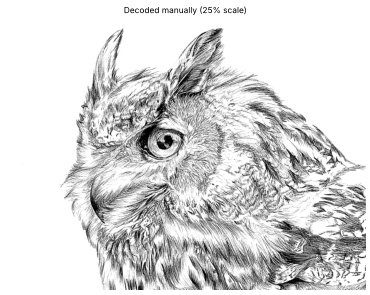

In [4]:
# Unpack the bits, remove the row padding, flip the rows, and apply the palette
row_bytes = ((width * bits_per_pixel + 31) // 32) * 4
print(f"Row: {width * bits_per_pixel / 8:.0f} bytes of pixels + padding = {row_bytes} bytes")

rows = np.frombuffer(raw, np.uint8, count=row_bytes * abs(height), offset=data_offset).reshape(abs(height), row_bytes)
indices = np.unpackbits(rows, axis=1)[:, :width]
if height > 0:
    indices = indices[::-1]
lut = np.array([p[2] for p in palette], np.uint8)        # red value (the palette is gray)
manual = lut[indices]

opencv = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_GRAYSCALE)
print("Manual decoding equals OpenCV:", np.array_equal(manual, opencv))
show([cv2.resize(manual, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)], ["Decoded manually (25% scale)"], size=(8, 6))

#### **Key Takeaways**

* Always unpack binary formats with an explicit byte order (`<` for little-endian) and the right signedness.
* BMP rows are padded to 4 bytes and stored bottom-up when the height is positive.
* Decoding by hand and comparing with a trusted library is a simple way to validate a parser.